In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.vaep import features as ft
from socceraction.vaep import labels as lab
from socceraction.vaep import formula as fm
from socceraction.atomic.spadl import convert_to_atomic

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_parquet('spadl_events/spadl.parquet')
df

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
0,13335,1,5,15620,0.503105,0.504544,0.326924,0.436265,12926009.0,153.887,0,pass,1,success,5,foot_right,0
1,13335,1,5,4696,0.329743,0.457456,0.760200,0.735603,12926647.0,156.623,0,pass,0,fail,5,foot_right,1
2,13335,1,5,14278,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,2
3,13335,1,11,284,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,1,success,0,foot,3
4,13335,1,5,13068,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
551573,20480,2,218,567,0.298400,0.550824,NaN,NaN,18703655.0,2830.097,9,tackle,1,success,0,foot,551573
551574,20480,2,218,567,0.296752,0.552118,0.273371,0.727029,18703656.0,2830.130,0,pass,1,success,1,head,551574
551575,20480,2,218,7252,0.280362,0.659956,0.305095,0.593382,18703661.0,2833.100,21,dribble,1,success,0,foot,551575
551576,20480,2,218,7252,0.305095,0.593382,0.118105,0.120397,18703665.0,2834.101,0,pass,1,success,5,foot_right,551576


In [4]:
## Mantendo apenas a primeira linha de cada event_id

df = df.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

In [5]:
df

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
151183,13439,2,10,247,0.781676,0.387618,0.846238,0.306147,15445829.0,0.033,0,pass,1,success,5,foot_right,151183
329721,13562,2,19,94,0.708276,0.036662,0.766562,0.005088,17164299.0,0.033,0,pass,1,success,4,foot_left,329721
106486,13408,2,221,230,0.564581,0.252632,0.474152,0.280985,14874531.0,0.033,0,pass,1,success,5,foot_right,106486
20984,13349,2,5,13068,0.776371,0.641338,0.693600,0.638941,14869343.0,0.067,0,pass,1,success,5,foot_right,20984
229776,13493,2,17,12785,0.187638,0.593176,0.611467,0.859691,16012239.0,0.067,0,pass,1,success,5,foot_right,229776
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528789,13699,2,2,265,0.653124,0.507103,0.683838,0.796824,20656337.0,3599.933,0,pass,1,success,5,foot_right,528789
434370,13634,2,17,8074,0.928314,0.688103,0.956381,0.470735,19266289.0,3599.933,0,pass,0,fail,5,foot_right,434370
121918,13419,2,10,1956,0.878962,0.084941,0.773029,0.212279,15182454.0,3599.933,0,pass,1,success,4,foot_left,121918
291203,13536,2,10,38,0.387838,0.488382,0.463952,0.418088,16656447.0,3599.966,0,pass,1,success,5,foot_right,291203


In [6]:
# Ordenar ações por tempo dentro de cada jogo
df = df.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

## SPADL --> SPADL-ATOMIC

In [7]:
df_atomic = convert_to_atomic(df)

In [8]:
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.8870,5,15620,0.503105,0.504544,-0.176181,-0.068279,0,5
1,13335,12926009.0,1,1,155.2550,5,4696,0.326924,0.436265,0.000000,0.000000,23,0
2,13335,12926647.0,2,1,156.6230,5,4696,0.329743,0.457456,0.430457,0.278147,0,5
3,13335,12926642.0,3,1,159.8600,5,14278,0.760200,0.735603,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.8930,11,284,0.760200,0.735603,-0.179133,0.151000,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
853074,20480,18703661.0,853074,2,2833.1000,218,7252,0.280362,0.659956,0.024733,-0.066574,21,0
853075,20480,18703665.0,853075,2,2834.1010,218,7252,0.305095,0.593382,-0.186990,-0.472985,0,5
853076,20480,18703665.0,853076,2,2836.9205,218,481,0.118105,0.120397,0.000000,0.000000,23,0
853077,20480,18703669.0,853077,2,2839.7400,218,481,0.008514,0.010029,-0.001476,0.468779,0,5


In [9]:
# from socceraction.spadl import config as spadlconfig

# max_type_id = len(spadlconfig.actiontypes) - 1

# df_atomic['type_name'] = df_atomic['type_id'].apply(
#         lambda x: spadlconfig.actiontypes[x] if x <= max_type_id else 'atomic_add'
#     )
# df_atomic

from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

In [10]:
df_atomic[df_atomic['dx'].isna()]['type_id'].value_counts()

type_id
9     48810
11    10699
0      9742
7      8699
10     5652
8      4583
23     1539
27     1319
14      864
21      415
18      207
Name: count, dtype: int64

In [11]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

In [12]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 1
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features: 100%|██████████| 380/380 [00:34<00:00, 10.87it/s]


In [13]:
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name
0,13335,12926009.0,0,1,153.8870,5,15620,0.503105,0.504544,-0.176181,-0.068279,0,5,pass
1,13335,12926009.0,1,1,155.2550,5,4696,0.326924,0.436265,0.000000,0.000000,23,0,receival
2,13335,12926647.0,2,1,156.6230,5,4696,0.329743,0.457456,0.430457,0.278147,0,5,pass
3,13335,12926642.0,3,1,159.8600,5,14278,0.760200,0.735603,NaN,NaN,9,0,tackle
4,13335,20246849.0,4,1,159.8930,11,284,0.760200,0.735603,-0.179133,0.151000,18,0,clearance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
853074,20480,18703661.0,853074,2,2833.1000,218,7252,0.280362,0.659956,0.024733,-0.066574,21,0,dribble
853075,20480,18703665.0,853075,2,2834.1010,218,7252,0.305095,0.593382,-0.186990,-0.472985,0,5,pass
853076,20480,18703665.0,853076,2,2836.9205,218,481,0.118105,0.120397,0.000000,0.000000,23,0,receival
853077,20480,18703669.0,853077,2,2839.7400,218,481,0.008514,0.010029,-0.001476,0.468779,0,5,pass


### Labels

In [14]:
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(str)
events_results = df.sort_values(by='time_seconds')[['original_event_id', 'result_name']].drop_duplicates(subset=['original_event_id'])
events_results['original_event_id'] = events_results['original_event_id'].astype(str)
df_atomic = df_atomic.merge(events_results, on='original_event_id', how='left')

In [15]:
import socceraction.atomic.vaep.labels as lab

Ycols = ["scores","concedes","result_name"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts), acts['result_name']], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels: 100%|██████████| 380/380 [00:49<00:00,  7.62it/s]


In [16]:
labels['result_name'] = labels['result_name'].replace({'success': 1, 'fail': 0})

### Divisão Treino/Teste/Classificador_sucesso

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.65, random_state=42)
train_idx, rest_idx = next(gss.split(df_atomic, groups=df_atomic.game_id))

# agora divide rest em test e classifier (metade/metade)
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
test_idx, classifier_idx = next(
    gss2.split(df_atomic.iloc[rest_idx], groups=df_atomic.game_id.iloc[rest_idx])
)

mask_train      = df_atomic.index.isin(train_idx)
mask_test       = df_atomic.index.isin(rest_idx[test_idx])
mask_classifier = df_atomic.index.isin(rest_idx[classifier_idx])


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)
X_classifier = features[mask_classifier].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)
y_classifier = labels[mask_classifier].reset_index(drop=True)



### Treino - Atomic VAEP 

In [18]:
models, yhat_train, yhat_test = {}, {}, {}
for target in ['scores', 'concedes']:
    print(f"\n### Treinando '{target}' ###")
    clf = XGBClassifier(
        n_estimators=50,
        max_depth=3,
        enable_categorical=True,
        n_jobs=-3,
    )
    clf.fit(X_train, y_train[target])
    models[target] = clf

    yhat_train[target] = clf.predict_proba(X_train)[:, 1]
    yhat_test[target] = clf.predict_proba(X_test)[:, 1]


### Treinando 'scores' ###

### Treinando 'concedes' ###


In [19]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

Y_hat_train, Y_hat_test = pd.DataFrame(), pd.DataFrame()
for col in ['scores', 'concedes']:
    Y_hat_train[col] = yhat_train[col]
    Y_hat_test[col]  = yhat_test[col]

for col in ['scores', 'concedes']:
    evaluate(y_train[col], Y_hat_train[col], label=f"{col} - TRAIN")
    evaluate(y_test[col] , Y_hat_test[col] , label=f"{col} - TEST")

### SCORES - TRAIN ###
  Brier score : 0.01129 (0.01145)
  Log loss    : 0.05753 (0.00162)
  ROC AUC     : 0.78455

### SCORES - TEST ###
  Brier score : 0.01096 (0.01111)
  Log loss    : 0.05704 (0.00160)
  ROC AUC     : 0.75149

### CONCEDES - TRAIN ###
  Brier score : 0.00220 (0.00220)
  Log loss    : 0.01374 (0.00038)
  ROC AUC     : 0.83835

### CONCEDES - TEST ###
  Brier score : 0.00207 (0.00208)
  Log loss    : 0.01378 (0.00038)
  ROC AUC     : 0.74752



## Classificador - Score

### Treino - Classificador

In [ ]:
models, yhat_train, yhat_test = {}, {}, {}

classificador_sucesso = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(1/y_classifier['result_name'].mean() - 1),
    enable_categorical=True,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# separa 10% de X_classifier para early stopping
from sklearn.model_selection import train_test_split
Xcs_tr, Xcs_val, ycs_tr, ycs_val = train_test_split(
    X_classifier, y_classifier['result_name'],
    test_size=0.1, stratify=y_classifier['result_name'], random_state=42
)

classificador_sucesso.fit(
    Xcs_tr, ycs_tr,
    eval_set=[(Xcs_val, ycs_val)],
    verbose=False
)

models['result_name'] = classificador_sucesso

yhat_train['result_name'] = classificador_sucesso.predict_proba(X_classifier)[:, 1]
yhat_test['result_name'] = classificador_sucesso.predict_proba(X_train)[:, 1]

In [21]:
Y_hat_train, Y_hat_test = pd.DataFrame(), pd.DataFrame()

Y_hat_train['result_name'] = yhat_train['result_name']
Y_hat_test['result_name']  = yhat_test['result_name']

evaluate(y_classifier['result_name'], Y_hat_train['result_name'], label=f"TRAIN")
evaluate(y_train['result_name'] , Y_hat_test['result_name'] , label=f"TEST")

### TRAIN ###
  Brier score : 0.12055 (0.15205)
  Log loss    : 0.38206 (0.01337)
  ROC AUC     : 0.90986

### TEST ###
  Brier score : 0.12386 (0.15586)
  Log loss    : 0.39064 (0.01364)
  ROC AUC     : 0.90237



## Atomic VAEP + Classificador_sucesso

In [22]:
## Scores
train_score = classificador_sucesso.predict_proba(X_train)[:, 1]
test_score = classificador_sucesso.predict_proba(X_test)[:, 1]

In [23]:
len(train_score)

556806

In [24]:
success_score_all = classificador_sucesso.predict_proba(features)[:, 1]
features['success_score'] = success_score_all

# — ALTERAÇÃO AQUI — Atualiza X_train e X_test com a coluna de sucesso
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test] .reset_index(drop=True)

In [25]:
X_train['success_score'] = train_score
X_test['success_score'] = test_score

In [26]:
X_train

,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,x_a0,y_a0,dist_to_goal_a0,angle_to_goal_a0,dx_a0,dy_a0,period_id_a0,time_seconds_a0,time_seconds_overall_a0,success_score
0,True,False,False,False,False,False,False,False,False,False,...,0.496324,0.501088,109.741494,0.310204,0.993576,0.113164,1,105.4050,105.4050,0.503995
1,False,False,False,False,False,False,False,False,False,False,...,0.694648,0.523676,109.545747,0.310560,0.000000,0.000000,1,107.3070,107.3070,0.949335
2,True,False,False,False,False,False,False,False,False,False,...,0.703343,0.454868,109.558517,0.311183,-0.828553,-0.559911,1,109.2090,109.2090,0.530275
3,False,False,False,False,False,False,False,False,False,False,...,0.242952,0.143750,110.092165,0.312592,0.000000,0.000000,1,110.3435,110.3435,0.073827
4,True,False,False,False,False,False,False,False,False,False,...,0.242952,0.143750,110.092165,0.312592,0.882825,0.469702,1,111.4780,111.4780,0.211977
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
556801,False,False,False,False,False,False,False,False,False,False,...,0.280362,0.659956,109.898868,0.308228,0.348261,-0.937398,2,2833.1000,5533.1000,0.998461
556802,True,False,False,False,False,False,False,False,False,False,...,0.305095,0.593382,109.895519,0.308873,-0.367653,-0.929963,2,2834.1010,5534.1010,0.732819
556803,False,False,False,False,False,False,False,False,False,False,...,0.118105,0.120397,110.218145,0.312446,0.000000,0.000000,2,2836.9205,5536.9205,0.778109
556804,True,False,False,False,False,False,False,False,False,False,...,0.008514,0.010029,110.356378,0.313092,-0.003149,0.999995,2,2839.7400,5539.7400,0.038019


In [27]:
models, yhat_train, yhat_test = {}, {}, {}
for target in ['scores', 'concedes']:
    print(f"\n### Treinando '{target}' ###")
    clf = XGBClassifier(
        n_estimators=50,
        max_depth=3,
        enable_categorical=True,
        n_jobs=-3,
    )
    clf.fit(X_train, y_train[target])
    models[target] = clf

    yhat_train[target] = clf.predict_proba(X_train)[:, 1]
    yhat_test[target] = clf.predict_proba(X_test)[:, 1]


### Treinando 'scores' ###

### Treinando 'concedes' ###


In [28]:
Y_hat_train, Y_hat_test = pd.DataFrame(), pd.DataFrame()
for col in ['scores', 'concedes']:
    Y_hat_train[col] = yhat_train[col]
    Y_hat_test[col]  = yhat_test[col]

for col in ['scores', 'concedes']:
    evaluate(y_train[col], Y_hat_train[col], label=f"{col} - TRAIN")
    evaluate(y_test[col] , Y_hat_test[col] , label=f"{col} - TEST")

### SCORES - TRAIN ###
  Brier score : 0.01129 (0.01144)
  Log loss    : 0.05732 (0.00161)
  ROC AUC     : 0.78965

### SCORES - TEST ###
  Brier score : 0.01097 (0.01111)
  Log loss    : 0.05707 (0.00160)
  ROC AUC     : 0.75294

### CONCEDES - TRAIN ###
  Brier score : 0.00220 (0.00221)
  Log loss    : 0.01377 (0.00038)
  ROC AUC     : 0.83623

### CONCEDES - TEST ###
  Brier score : 0.00207 (0.00208)
  Log loss    : 0.01376 (0.00038)
  ROC AUC     : 0.75162



## Predições - Jogadores

In [29]:
# ==========================
# 6. PREDIÇÕES
# ==========================

def generate_predictions(features, models):
    preds = {}
    for m in ['scores', 'concedes']:
        preds[m] = models[m].predict_proba(features)[:, 1]
    return pd.DataFrame(preds)

preds_my = generate_predictions(features, models)


In [30]:
def calculate_action_values(spadl, predictions):
    values = fm.value(actions=spadl, Pscores=predictions['scores'], Pconcedes=predictions['concedes'])
    return pd.concat([
        spadl[['game_id', 'action_id', 'player_id', 'type_name']],  # Removi colunas que não existem
        predictions.rename(columns={'scores': 'Pscores', 'concedes': 'Pconcedes'}),
        values
    ], axis=1)


In [31]:
# ==========================
# 7. CÁLCULO DO VAEP
# ==========================
vaep_my = calculate_action_values(df_atomic, preds_my)

# ==========================
# 8. RESULTADOS FINAIS
# ==========================
print(vaep_my.sort_values('vaep_value', ascending=False).head())

vaep_by_player = vaep_my.groupby('player_id')['vaep_value'].mean().sort_values(ascending=False)
print("\nVAEP médio por jogador:")
print(vaep_by_player.head())

       game_id  action_id player_id type_name  Pscores  Pconcedes  \
156287   13404     156287     10715      goal      1.0   0.003478   
44636    13355      44636       134      goal      1.0   0.004546   
15459    13342      15459      5116      goal      1.0   0.001518   
433181   13529     433181       596      goal      1.0   0.001518   
439928   13532     439928      4152      goal      1.0   0.001187   

        offensive_value  defensive_value  vaep_value  
156287         0.971432        -0.002314    0.969118  
44636          0.970046        -0.001949    0.968098  
15459          0.968339        -0.000517    0.967823  
433181         0.966577        -0.000390    0.966186  
439928         0.965842        -0.000561    0.965281  

VAEP médio por jogador:
player_id
7243     0.054102
4687     0.039876
5089     0.032466
14728    0.030673
29048    0.029017
Name: vaep_value, dtype: float32


In [32]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    
    Parâmetros:
    y_train, y_test: rótulos verdadeiros (séries ou arrays).
    yhat_train, yhat_test: probabilidades previstas pelo modelo.
    label: nome do alvo ("scores" ou "concedes").
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10)
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10)

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid()

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.legend()
    plt.grid()

    # -------- Distribuição das Probabilidades Previstas --------
    # plt.subplot(1, 3, 3)
    # sns.kdeplot(yhat_train, label='Treino', shade=True)
    # sns.kdeplot(yhat_test, label='Teste', shade=True)
    # plt.title(f'Distribuição de Probabilidades - {label}')
    # plt.xlabel('Probabilidade prevista')
    # plt.ylabel('Densidade')
    # plt.legend()
    # plt.grid()

    plt.tight_layout()
    plt.show()

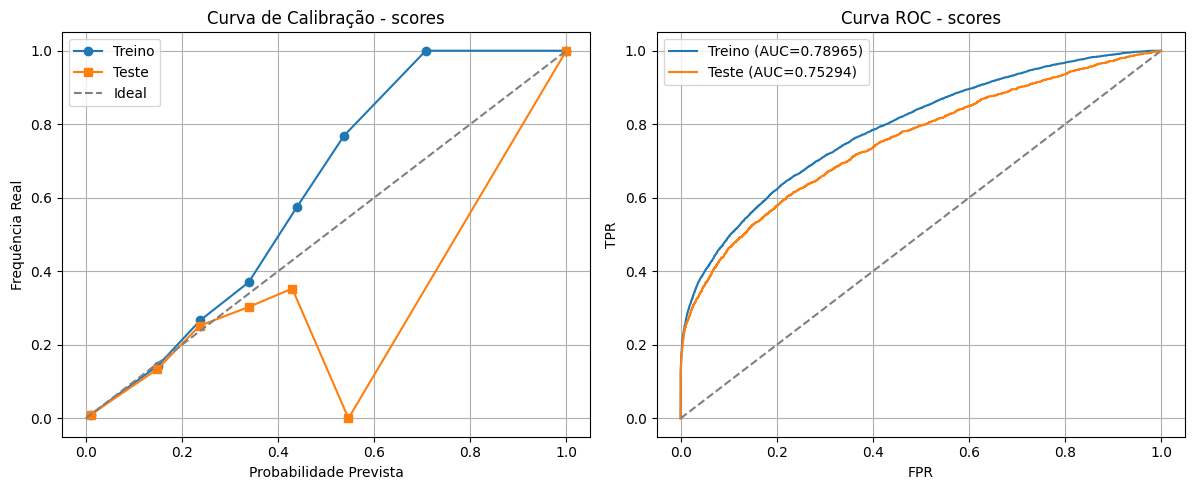

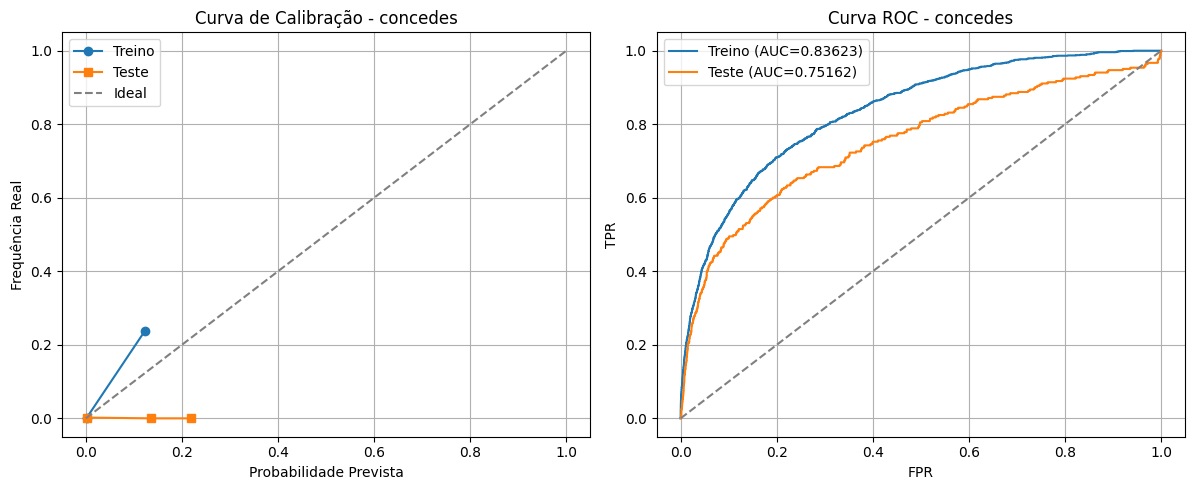

In [33]:
Ycols = [col for col in Ycols if col != 'result_name']

for col in Ycols:
    plot_model_diagnostics(y_train[col], y_test[col], Y_hat_train[col], Y_hat_test[col], label=col)